In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv('../../course_assignments/homework9/solar_system.csv')

In [3]:
print(df.shape) # 20 rows, 11 columns
print(df.head(5))
print(df.tail(5))
print(df.columns) # 'Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter','Saturn', 'Uranus', 'Neptune', 'Pluto'

(20, 11)
                Attribute Mercury  Venus  Earth   Moon   Mars Jupiter  Saturn  \
0          Mass (10^24kg)   0.330   4.87   5.97  0.073  0.642    1898     568   
1           Diameter (km)    4879  12104  12756   3475   6792  142984  120536   
2        Density (kg/m^3)    5429   5243   5514   3340   3934    1326     687   
3         Gravity (m/s^2)     3.7    8.9    9.8    1.6    3.7    23.1     9.0   
4  Escape Velocity (km/s)     4.3   10.4   11.2    2.4    5.0    59.5    35.5   

  Uranus Neptune   Pluto  
0   86.8     102  0.0130  
1  51118   49528    2376  
2   1270    1638    1850  
3    8.7    11.0     0.7  
4   21.3    23.5     1.3  
                  Attribute Mercury Venus Earth Moon  Mars  Jupiter   Saturn  \
15     Mean Temperature (C)     167   464    15  -20   -65     -110     -140   
16  Surface Pressure (bars)       0    92     1    0  0.01  Unknown  Unknown   
17          Number of Moons       0     0     1    0     2       95      274   
18             Ring Sy

In [4]:
print(df['Attribute'])

0                  Mass (10^24kg)
1                   Diameter (km)
2                Density (kg/m^3)
3                 Gravity (m/s^2)
4          Escape Velocity (km/s)
5         Rotation Period (hours)
6           Length of Day (hours)
7     Distance from Sun (10^6 km)
8            Perihelion (10^6 km)
9              Aphelion (10^6 km)
10          Orbital Period (days)
11        Orbital Velocity (km/s)
12      Orbital Inclination (deg)
13           Orbital Eccentricity
14       Obliquity to Orbit (deg)
15           Mean Temperature (C)
16        Surface Pressure (bars)
17                Number of Moons
18                   Ring System?
19         Global Magnetic Field?
Name: Attribute, dtype: str


In [5]:
op = df.drop(columns = ['Attribute']).iloc[10].astype(float)
pe = df.drop(columns = ['Attribute']).iloc[8].astype(float)
ap = df.drop(columns = ['Attribute']).iloc[9].astype(float)

In [6]:
# perihelion: the point the planet is closest to sun in orbit
# aphelion: the point the planet is most away from the sun
# semi-major axis: longest axis on an ellipse

In [7]:
a = (pe+ap)/2
print(a)

Mercury      57.9000
Venus       108.2000
Earth       149.6000
Moon          0.3845
Mars        228.0000
Jupiter     778.5000
Saturn     1432.0500
Uranus     2867.0500
Neptune    4515.0000
Pluto      5906.3500
dtype: float64


In [8]:
new_row = pd.Series(
    ['Semi-major axis (10^6 km)'] + a.tolist(), 
    index=df.columns
)
df = pd.concat([df, new_row.to_frame().T], ignore_index=True)

In [9]:
print(df.shape) # 21 rows, 11 columns

(21, 11)


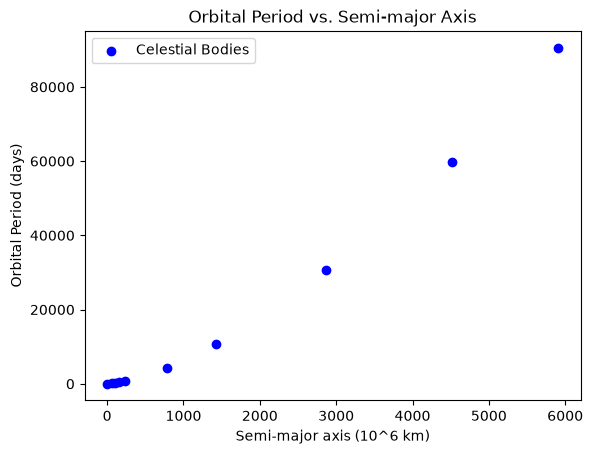

In [10]:
plt.figure()
plt.scatter(a, op, color='blue', marker='o', label='Celestial Bodies')
plt.xlabel('Semi-major axis (10^6 km)')
plt.ylabel('Orbital Period (days)')
plt.title('Orbital Period vs. Semi-major Axis')
plt.legend()
plt.show()

In [11]:
def keplers_third_law(a, m):
    return m * a ** 1.5

In [12]:
popt, pcov = curve_fit(keplers_third_law, a, op)
m_fit = popt[0]
print(f"Fit: op = {m_fit:.2f} * a ^ 1.5 ")

Fit: op = 0.20 * a ^ 1.5 


In [13]:
residuals = op - keplers_third_law(a, m_fit)
chi2 = np.sum(residuals**2)
dof = len(a) - len(popt)
chi2_reduced = chi2 / dof
print(chi2_reduced)

41276.70608939402


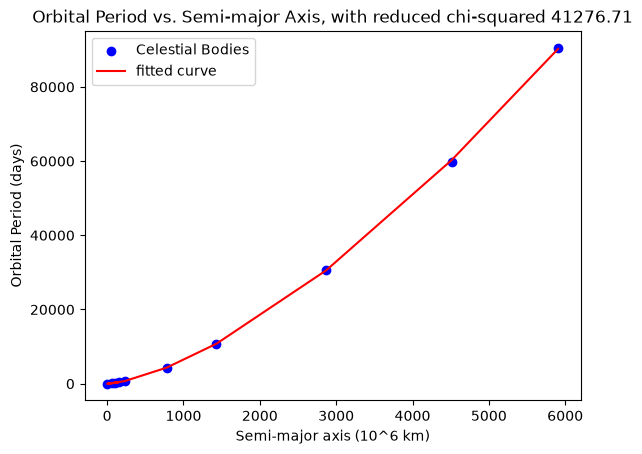

In [14]:
plt.figure()
plt.scatter(a, op, color='blue', marker='o', label='Celestial Bodies')
plt.plot(a, keplers_third_law(a, m_fit), color = 'red', label = 'fitted curve')
plt.xlabel('Semi-major axis (10^6 km)')
plt.ylabel('Orbital Period (days)')
plt.title(f'Orbital Period vs. Semi-major Axis, with reduced chi-squared {chi2_reduced:.2f}')
plt.legend()
plt.show()

In [15]:
df.to_csv("kepler.csv", index=False)